<a href="https://colab.research.google.com/github/aderemi1224/Guest_Sentiment/blob/main/topic_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/aderemi1224/Guest_Sentiment.git
%cd Guest_Sentiment

Cloning into 'Guest_Sentiment'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 16 (delta 2), reused 13 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (16/16), 2.72 MiB | 9.38 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/Guest_Sentiment


In [ ]:
!pip install bertopic sentence-transformers umap-learn hdbscan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 5.2 MB/s eta 0:00:00


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving montra_cleaned_data.csv to montra_cleaned_data.csv


In [ ]:
import re
import pandas as pd
import numpy as np
from pathlib import Path

In [ ]:
DATA_DIR = Path("../data/processed")
DATA_DIR.mkdir(parents =True, exist_ok = True)

In [ ]:
merged = pd.read_csv("montra_cleaned_data.csv")
merged.head()

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,...,stay_duration,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms,cleaned_review_text
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,Suite,Direct Website,...,1,Leisure,NaN,France,4,The Aberdeen Grand,Aberdeen,4,118,the overall price was fair for what we paid mi...
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,Deluxe,Corporate Portal,...,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,the room was nothing out of the ordinary for w...
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,Executive,Travel Agent,...,2,Business,NaN,Ireland,4,The London Boutique,London,4,231,unfortunately the pool was outdated it clearly...
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,Family Room,Airbnb,...,3,Leisure,NaN,Nigeria,0,Manchester Metropolitan,Manchester,3,101,we were disappointed that the neighborhood was...
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,Deluxe,Expedia,...,5,Group,NaN,United States,9,Glasgow Metropolitan,Glasgow,4,214,the room service was standard hotel fare for w...


In [ ]:
document = (merged['cleaned_review_text'].astype(str).tolist())
print(f'Total document {len(document)}')
document[:3]

Total document 35000


['the overall price was fair for what we paid might consider it again might not',
 'the room was nothing out of the ordinary for what we paid the overall price exceeded our expectations a great deal and the quality easily matched the price',
 'unfortunately the pool was outdated it clearly needed some upkeep wouldn t recommend it to others']

In [ ]:
UK_Cities = ["London", "Manchester", "Edinburgh", "Birmingham","Leeds","Bristol", "Liverpool", "Glasgow","Oxford","Bath","York","Cardiff", "New Castle", "Nottingham","Brighton","Sheffield","Leicester","Belfast","Southampton", "Aberdeen"]
city_pattern = re.compile(r'\b(' + '|'.join(UK_Cities) + r')\b', re.IGNORECASE)
document = [city_pattern.sub('',doc).strip() for doc in document]
document = [re.sub(r'\s+',' ', doc) for doc in document]

In [ ]:
from collections import Counter
import torch
from sentence_transformers import SentenceTransformer
from pathlib import Path
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

In [ ]:
normalized_docs = [doc.lower().strip() for doc in document]

## Count exact duplicate
total_docs = len(normalized_docs)
unique_docs = len(set(normalized_docs))
duplicated_docs = total_docs - unique_docs


print(f"Total documents: {total_docs}")
print(f"Unique documents: {unique_docs}")
print(f"Duplicated documents: {duplicated_docs}")

if total_docs > 0:
  duplicated_rate = duplicated_docs/total_docs *100
  print(f'Duplicated_rate: {duplicated_rate:.2f}%')

Total documents: 35000
Unique documents: 34400
Duplicated documents: 600
Duplicated_rate: 1.71%


In [ ]:
### Calculate vocabulary size
all_words = " ".join(normalized_docs).split()
print(f"Vocab size: {len(set(all_words))}")

### Display the first 20 common words
print(Counter(all_words).most_common(20))


Vocab size: 507
[('the', 73552), ('was', 54683), ('we', 32665), ('nothing', 24495), ('our', 23913), ('in', 23668), ('to', 18777), ('for', 18311), ('what', 17937), ('a', 17697), ('and', 17560), ('that', 16124), ('about', 12575), ('overall', 12124), ('it', 11539), ('paid', 11056), ('stay', 11027), ('as', 11012), ('out', 10561), ('i', 10224)]


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [ ]:
embedding_model = SentenceTransformer("all-mpnet-base-v2", device = device)

EMB_PATH = DATA_DIR/"review-embeddings.npy"

if EMB_PATH.exists():
  embeddings = np.load(EMB_PATH)
  print("Loaded cached embeddings:", embeddings.shape)
else:
  embeddings = embedding_model.encode(
      document,
      batch_size = 64,
      show_progress_bar = True
  )
  np.save(EMB_PATH, embeddings)
  print("Computed and saved embedding:", embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/547 [00:00<?, ?it/s]

Computed and saved embedding: (35000, 768)


In [ ]:
embeddings[:2]

array([[-0.00413856,  0.01629657,  0.01087651, ...,  0.00215244,
         0.00641585, -0.01160033],
       [-0.00784516, -0.04081137,  0.01082292, ...,  0.01583503,
         0.04026258,  0.02184933]], dtype=float32)

In [ ]:
### Configure the UMAP
umap_model = UMAP(
    n_neighbors= 15,
    n_components = 5,
    min_dist= 0.0,
    metric = "cosine",
    random_state = 42
)

In [ ]:
### Configure HDBSCAN
hdbscan_model =HDBSCAN(
    min_cluster_size = 800,
    min_samples = 100,
    metric ='euclidean',
    cluster_selection_method = 'eom',
    prediction_data = True
)

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer_model = CountVectorizer(
    stop_words = "english",
    ngram_range =(1, 5),
    min_df =5
)

In [ ]:
topic_model = BERTopic(
    embedding_model =embedding_model,
    umap_model = umap_model,
    hdbscan_model = hdbscan_model,
    vectorizer_model=vectorizer_model,
    calculate_probabilities = True,
    verbose = True
)

print(topic_model.vectorizer_model)
topics, probabilities = topic_model.fit_transform(document, embeddings)
print(topic_model.vectorizer_model)

2026-10-20 11:00:17,575 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


CountVectorizer(min_df=5, ngram_range=(1, 5), stop_words='english')


2026-10-20 11:01:24,507 - BERTopic - Dimensionality - Completed ✓
2026-10-20 11:01:24,509 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-20 11:01:36,478 - BERTopic - Cluster - Completed ✓
2026-10-20 11:01:36,493 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-20 11:01:38,572 - BERTopic - Representation - Completed ✓


CountVectorizer(min_df=5, ngram_range=(1, 5), stop_words='english')


In [ ]:
topic_model.reduce_topics(document, nr_topics="auto")

2026-10-20 11:01:38,861 - BERTopic - Topic reduction - Reducing number of topics
2026-10-20 11:01:38,878 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-20 11:01:40,878 - BERTopic - Representation - Completed ✓
2026-10-20 11:01:40,884 - BERTopic - Topic reduction - Reduced number of topics from 11 to 11


In [ ]:
new_topics = topic_model.reduce_outliers(document, topics, strategy="c-tf-idf")

topic_model.update_topics(
    document,
    topics=new_topics,
    vectorizer_model=vectorizer_model
)

print(topic_model.vectorizer_model)
print(topic_model.get_topic(0))

2026-10-20 11:01:41,217 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


CountVectorizer(min_df=5, ngram_range=(1, 5), stop_words='english')
[('overall', np.float64(0.024595638435370264)), ('stay', np.float64(0.024280122766706706)), ('paid', np.float64(0.022913357280923877)), ('expected', np.float64(0.021492469487415636)), ('fine', np.float64(0.01865844182655382)), ('time', np.float64(0.01764210482212636)), ('hotel', np.float64(0.016125578242645197)), ('area', np.float64(0.013956680279977325)), ('acceptable', np.float64(0.01304899687786162)), ('staff', np.float64(0.012740378540889916))]


In [ ]:
merged["topic"] = topics
merged[["review_text","topic"]].head(10)

,review_text,topic
0,The overall price was fair for what we paid. M...,0
1,The room was nothing out of the ordinary for w...,0
2,"Unfortunately, the pool was outdated — it clea...",2
3,We were disappointed that the neighborhood was...,0
4,The room service was standard hotel fare for w...,0
5,Getting around from the hotel was in a rather ...,0
6,We couldn't have asked for a better base while...,4
7,We had a wonderful time during our stay in Not...,0
8,The in-house cafe was acceptable for what we p...,1
9,"The manager was fine, nothing special for what...",1


In [ ]:
info = topic_model.get_topic_info()
print(f"Total topics (excl. outliers): {len(info) - 1}")
print(f"Outlier count: {info[info['Topic'] == -1]['Count'].values}")
info.sort_values('Count', ascending=False).head(20)

Total topics (excl. outliers): 9
Outlier count: []


,Topic,Count,Name,Representation,Representative_Docs
0,0,23600,0_overall_stay_paid_expected,"[overall, stay, paid, expected, fine, time, ho...",[this hotel was a fine if unremarkable choice ...
1,1,2061,1_gym_fitness_facilities_fitness facilities,"[gym, fitness, facilities, fitness facilities,...",[sadly the fitness facilities turned out to be...
2,2,2025,2_spa_pool_overall_fine,"[spa, pool, overall, fine, paid, expected, sta...",[this hotel was a fine if unremarkable choice ...
3,3,1336,3_visit stood_visit stood way_stood way_way,"[visit stood, visit stood way, stood way, way,...",[nothing about our visit to stood out much eit...
4,4,1174,4_couldn asked better_visiting_couldn asked be...,"[couldn asked better, visiting, couldn asked b...",[we couldn t have asked for a better base whil...
5,5,1049,5_time truly_time truly memorable_truly memora...,"[time truly, time truly memorable, truly memor...",[this hotel made our time in truly memorable a...
6,6,977,6_business center_center_business_overall busi...,"[business center, center, business, overall bu...",[nothing about our visit to stood out much eit...
7,7,961,7_lounge_overall_expected_fine,"[lounge, overall, expected, fine, stay, paid, ...",[our arrival experience was fine nothing more ...
8,8,943,8_high hopes hotel_high hopes_hopes hotel let_...,"[high hopes hotel, high hopes, hopes hotel let...",[we had high hopes for this hotel in but were ...
9,9,874,9_fi_wi_wi fi_fine,"[fi, wi, wi fi, fine, overall, paid, expected,...",[our stay in was fairly ordinary also the wi f...


In [ ]:
import numpy as np
unique, counts = np.unique(topics, return_counts=True)
print(f"Number of topics: {len(unique)}")
print(f"Outliers (-1): {counts[unique == -1]}")
print(f"Topic size distribution — min: {counts.min()}, max: {counts.max()}, median: {np.median(counts)}")

Number of topics: 11
Outliers (-1): [793]
Topic size distribution — min: 793, max: 22997, median: 1042.0


In [ ]:
# 1. Correctly find the actual largest real topic
info = topic_model.get_topic_info()
real_topics = info[info['Topic'] != -1].sort_values('Count', ascending=False)
biggest_topic_id = real_topics.iloc[0]['Topic']
print(f"Biggest topic: {biggest_topic_id}, size: {real_topics.iloc[0]['Count']}")
print(topic_model.get_topic(biggest_topic_id))

mask = np.array(topics) == biggest_topic_id
print(merged.loc[mask, 'sentiment_label'].value_counts())

# 2. Check whether topics are splitting by city rather than theme
for _, row in real_topics.head(27).iterrows():
    words = [w for w, _ in topic_model.get_topic(row['Topic'])[:5]]
    print(row['Topic'], row['Count'], words)

Biggest topic: 0, size: 23600
[('overall', np.float64(0.024595638435370264)), ('stay', np.float64(0.024280122766706706)), ('paid', np.float64(0.022913357280923877)), ('expected', np.float64(0.021492469487415636)), ('fine', np.float64(0.01865844182655382)), ('time', np.float64(0.01764210482212636)), ('hotel', np.float64(0.016125578242645197)), ('area', np.float64(0.013956680279977325)), ('acceptable', np.float64(0.01304899687786162)), ('staff', np.float64(0.012740378540889916))]
sentiment_label
neutral     8954
positive    7303
negative    6740
Name: count, dtype: int64
0 23600 ['overall', 'stay', 'paid', 'expected', 'fine']
1 2061 ['gym', 'fitness', 'facilities', 'fitness facilities', 'overall']
2 2025 ['spa', 'pool', 'overall', 'fine', 'paid']
3 1336 ['visit stood', 'visit stood way', 'stood way', 'way', 'visit']
4 1174 ['couldn asked better', 'visiting', 'couldn asked better base', 'couldn', 'couldn asked better base visiting']
5 1049 ['time truly', 'time truly memorable', 'truly mem

In [ ]:
print(topic_model.vectorizer_model)

CountVectorizer(min_df=5, ngram_range=(1, 5), stop_words='english')


In [ ]:
topic_labels = {
    0: "General Neutral Feedback",       # overall, stay, paid, expected, fine
    1: "Fitness Facilities",             # gym, fitness, facilities
    2: "Spa & Pool Facilities",          # spa, pool
    3: "General Positive Feedback",      # visit stood way
    4: "General Positive Feedback",      # couldn't have asked for better
    5: "General Positive Feedback",      # time truly memorable
    6: "Business Center",                # business center
    7: "Lounge Facilities",              # lounge
    8: "General Dissatisfaction",        # high hopes, hotel, let down
    9: "Wi-Fi & Connectivity",           # wi-fi
    -1: "Unclassified",
}

merged["topic_category"] = new_topics
merged["topic_category"] = (
    merged["topic_category"]
    .map(topic_labels)
    .fillna("Unclassified")
)

display(merged[["review_text", "topic_category"]].head(20))

,review_text,topic_category
0,The overall price was fair for what we paid. M...,General Neutral Feedback
1,The room was nothing out of the ordinary for w...,General Neutral Feedback
2,"Unfortunately, the pool was outdated — it clea...",Spa & Pool Facilities
3,We were disappointed that the neighborhood was...,General Neutral Feedback
4,The room service was standard hotel fare for w...,General Neutral Feedback
5,Getting around from the hotel was in a rather ...,General Neutral Feedback
6,We couldn't have asked for a better base while...,General Positive Feedback
7,We had a wonderful time during our stay in Not...,General Neutral Feedback
8,The in-house cafe was acceptable for what we p...,Fitness Facilities
9,"The manager was fine, nothing special for what...",Fitness Facilities


,Topic,Review_Count
0,General Neutral Feedback,23600
1,General Positive Feedback,3559
2,Fitness Facilities,2061
3,Spa & Pool Facilities,2025
4,Business Center,977
5,Lounge Facilities,961
6,General Dissatisfaction,943
7,Wi-Fi & Connectivity,874


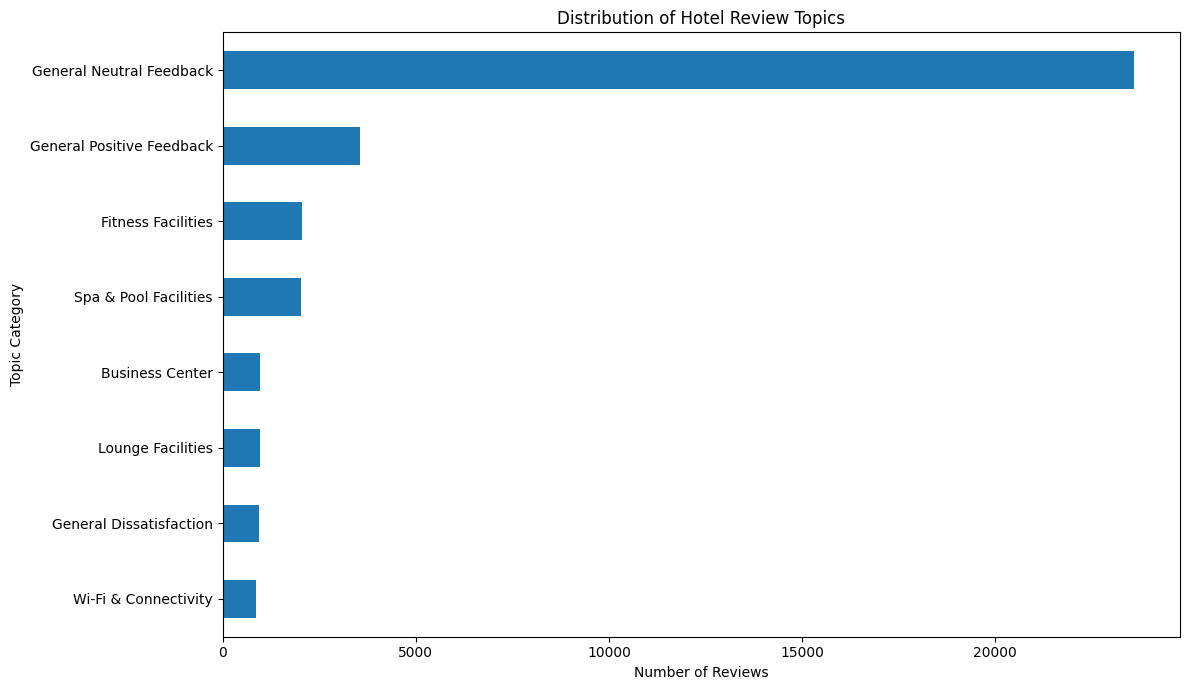

sentiment_label,negative,neutral,positive
topic_category,,,
Business Center,268,415,294
Fitness Facilities,592,832,637
General Dissatisfaction,900,43,0
General Neutral Feedback,6916,9174,7510
General Positive Feedback,59,1294,2206
Lounge Facilities,295,388,278
Spa & Pool Facilities,603,839,583
Wi-Fi & Connectivity,230,370,274


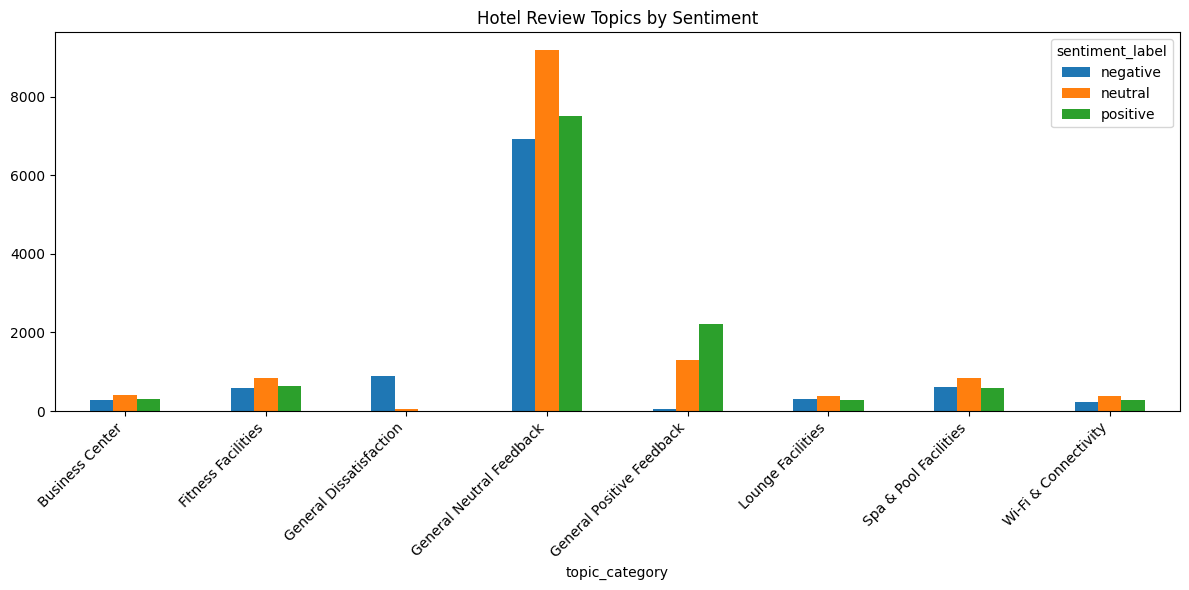

,rating_score
topic_category,
General Dissatisfaction,1.899152
Lounge Facilities,2.931113
Spa & Pool Facilities,2.947704
Business Center,2.981474
Fitness Facilities,2.983406
General Neutral Feedback,2.994436
Wi-Fi & Connectivity,3.007437
General Positive Feedback,3.659539


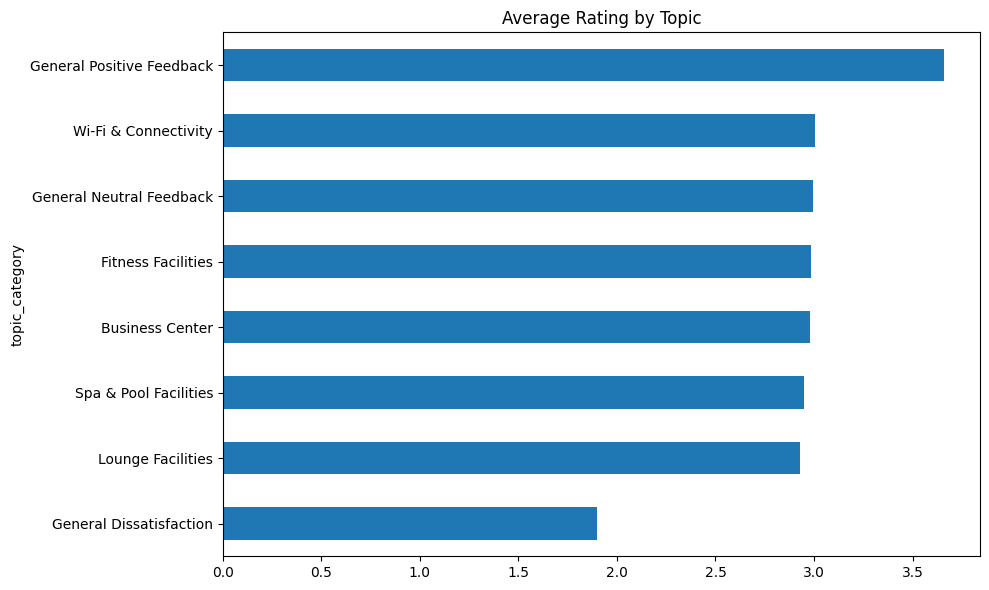

In [ ]:
# Topic distribution
topic_distribution = merged["topic_category"].value_counts().reset_index()
topic_distribution.columns = ["Topic", "Review_Count"]
display(topic_distribution)

import matplotlib.pyplot as plt

topic_distribution.sort_values("Review_Count").plot(
    x="Topic", y="Review_Count", kind="barh", legend=False, figsize=(12, 7)
)
plt.title("Distribution of Hotel Review Topics")
plt.xlabel("Number of Reviews")
plt.ylabel("Topic Category")
plt.tight_layout()
plt.show()

# Topic vs sentiment
topic_sentiment = pd.crosstab(merged["topic_category"], merged["sentiment_label"])
display(topic_sentiment)

topic_sentiment.plot(kind="bar", figsize=(12, 6))
plt.title("Hotel Review Topics by Sentiment")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Topic vs average rating
topic_rating = merged.groupby("topic_category")["rating_score"].mean().sort_values()
display(topic_rating)

topic_rating.plot(kind="barh", figsize=(10, 6))
plt.title("Average Rating by Topic")
plt.tight_layout()
plt.show()

In [ ]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
topic_model.save(
    str(MODEL_DIR / "hotel_review_topic_model"),
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-mpnet-base-v2",
)